# Домашнее задание 5

**Цель задания**:

Спроектировать и реализовать объектную модель учёта банковских операций с опорой на материалы тем 1–5 (файлы, datetime, pandas, регулярные выражения, ООП).

**Контекст**

Нужна небольшая модель учёта банковских счетов: расчётный и сберегательный счёт. Система должна вести историю операций, валидировать входные данные, отличать успешные операции от отклонённых и давать простую аналитику.

## Задание 1.
Реализуйте модель банковского счёта, которая не только меняет баланс, но и ведёт детальную историю действий.

### Этап 1.
**Правила**

- Счёт открывается с именем владельца и начальным балансом. Начальный баланс не может быть отрицательным (по умолчанию - 0).

- Номер счёта формируется автоматически в формате ACC-XXXX, где XXXX - порядковый номер. Счётчик номеров начинается с 1000. Номера счетов должны быть уникальными.

- Поддерживаются операции пополнения и снятия:

    1. Сумма операции должна быть положительной.

    2. Некорректная сумма приводит к исключению.

    3. При успехе баланс обновляется, в историю добавляется запись со статусом успешной операции.

    4. Если средств недостаточно, баланс не меняется, но попытка обязательно фиксируется в истории со статусом неуспешной операции.

- Каждая запись истории — структурированные данные. Минимум полей: тип операции (deposit / withdraw), сумма, дата и время, баланс после операции, статус (success / fail). Для даты и времени используйте модуль datetime.

- Должна быть возможность узнать текущий баланс и получить историю операций в удобном для чтения виде.

**Демонстрация**

В ноутбуке покажите:

- создание счёта;

- несколько успешных пополнений и снятий;

- хотя бы одну неуспешную попытку снятия;

- вывод баланса и истории.

In [1]:
from datetime import datetime
import matplotlib.pyplot as plt

In [2]:
class Account:
    _next_account_number = 1000 
    
    def __init__(self, name, balance=0):
        
        if balance < 0:
            raise ValueError("Начальный баланс не может быть отрицательным.")
        
        self.name = name
        self.balance = balance

        self.number = f"ACC-{Account._next_account_number}"
        Account._next_account_number += 1
        
        self.history = []

        operation = {
            "type": "opening",
            "amount": self.balance,
            "timestamp": datetime.now(),
            "balance_after": self.balance,
            "status": "open"
        }
        self.history.append(operation)

    def deposit(self, amount):
        """Метод для пополнения счета"""
        if amount <= 0:
            raise ValueError("Сумма операции должна быть положительной.")
            
        self.balance += amount
        
        operation = {
            "type": "deposit",
            "amount": amount,
            "timestamp": datetime.now(),
            "balance_after": self.balance,
            "status": "success"
        }
        self.history.append(operation)
        print(f"Счет успешно пополнен на {amount} руб.")

    def withdraw(self, amount):
        """Метод для снятия денег со счета"""
        if amount <= 0:
            raise ValueError("Сумма операции должна быть положительной.")
            
        if amount > self.balance:
            operation = {
                "type": "withdraw",
                "amount": amount,
                "timestamp": datetime.now(),
                "balance_after": self.balance,
                "status": "fail"
            }
            self.history.append(operation)
            print(f"Ошибка: Недостаточно средств для снятия {amount} руб.")
            return
            
        self.balance -= amount
        
        operation = {
            "type": "withdraw",
            "amount": amount,
            "timestamp": datetime.now(),
            "balance_after": self.balance,
            "status": "success"
        }
        self.history.append(operation)
        print(f"Со счета успешно снято {amount} руб.")

    def get_balance(self):
        """Метод для получения текущего баланса"""
        return self.balance

    def print_history(self):
        """Метод для вывода истории операций в красивом, читаемом виде"""
        print(f"\n--- История операций по счету {self.number} ({self.name}) ---")
        if not self.history:
            print("Операций пока не было.")
            return
            
        for record in self.history:
            time_str = record["timestamp"].strftime("%d.%m.%Y %H:%M:%S")

            if record["status"] == "success" or record["status"] == "open":
                status_text = "Успешно"
            else:
                status_text = "ОТКЛОНЕНО"

            if record["type"] == "deposit":
                type_text = "Пополнение"
            elif record["type"] == "opening":
                type_text = "Открытие"
            else:
                type_text =  "Снятие"
            
            print(f"[{time_str}] {type_text}: {record['amount']} руб. | Статус: {status_text} | Баланс после: {record['balance_after']} руб.")
        print("-" * 50)


    def plot_balance_history(self):
        """Метод для построения линейного графика изменения баланса"""
        
        if not self.history:
            print("История операций пуста. График построить нельзя.")
            return
            
        times = []
        balances = []
        
        for record in self.history:
            time_formatted = record["timestamp"].strftime("%H:%M:%S")
            times.append(time_formatted)
            balances.append(record["balance_after"])
            
        plt.figure(figsize=(10, 5))

        plt.plot(times, balances, marker='o', color='blue', linestyle='-', linewidth=2)
        
        plt.title(f"Изменение баланса по счету {self.number} ({self.name})")
        plt.xlabel("Время операции (ЧЧ:ММ:СС)")
        plt.ylabel("Баланс после операции (руб.)")
        plt.grid(True)
        
        plt.xticks(rotation=45)

        plt.tight_layout()
        
        plt.show()

**Демонстрация**

In [3]:
olga = Account(name='Ольга', balance=1000)

In [4]:
print(f"Владелец: {olga.name}, Номер счета: {olga.number}, Баланс: {olga.get_balance()} руб.\n")

Владелец: Ольга, Номер счета: ACC-1000, Баланс: 1000 руб.



In [5]:
olga.deposit(500)

Счет успешно пополнен на 500 руб.


In [6]:
olga.withdraw(300)

Со счета успешно снято 300 руб.


In [7]:
olga.deposit(200)

Счет успешно пополнен на 200 руб.


In [8]:
olga.withdraw(5000)

Ошибка: Недостаточно средств для снятия 5000 руб.


In [9]:
olga.print_history()


--- История операций по счету ACC-1000 (Ольга) ---
[23.10.2026 23:08:57] Открытие: 1000 руб. | Статус: Успешно | Баланс после: 1000 руб.
[23.10.2026 23:08:59] Пополнение: 500 руб. | Статус: Успешно | Баланс после: 1500 руб.
[23.10.2026 23:09:00] Снятие: 300 руб. | Статус: Успешно | Баланс после: 1200 руб.
[23.10.2026 23:09:01] Пополнение: 200 руб. | Статус: Успешно | Баланс после: 1400 руб.
[23.10.2026 23:09:02] Снятие: 5000 руб. | Статус: ОТКЛОНЕНО | Баланс после: 1400 руб.
--------------------------------------------------


In [10]:
olga.deposit(-50)

ValueError: Сумма операции должна быть положительной.

## Этап 2.
По истории операций постройте линейный график изменения баланса во времени (ось X - время операции, ось Y - баланс после операции). У графика должны быть заголовок и подписи осей.

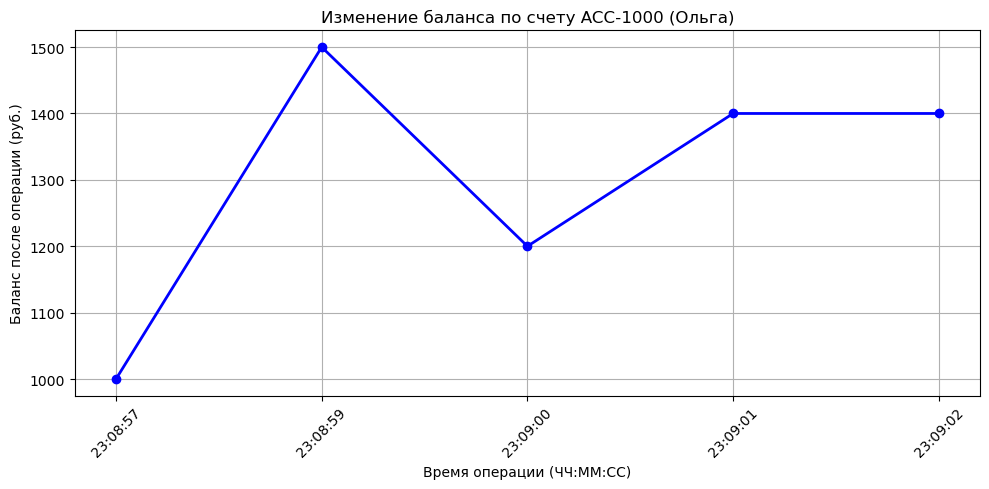

In [11]:
olga.plot_balance_history()

## Задание 2. Разные типы счетов и аналитика
Расчётный и сберегательный счета должны отражать общее поведение учёта операций, но отличаться правилами.

**Правила**

Расчётный счёт - базовые пополнение и снятие без дополнительных ограничений на долю снимаемой суммы.

Сберегательный счёт: умеет начислять проценты на текущий остаток (ставку задаёт вызывающий код, например 7%); нельзя снять больше 50% текущего баланса; нарушающая правило попытка не меняет баланс и фиксируется в истории как неуспешная.

У каждого типа счёта должен быть различимый тип (чтобы по объекту/данным было понятно, расчётный это счёт или сберегательный).

Валидация имени владельца: формат «Имя Фамилия», слова с заглавной буквы, кириллица или латиница. Иначе - исключение. Для проверки используйте регулярные выражения.

Аналитика по истории: возможность получить последние N крупных успешных операций (порог «крупности» и N задаёт вызывающий код).

**Демонстрация**

В ноутбуке покажите:

- создание расчётного и сберегательного счета;

- покажите начисление процентов на сберегательном;

- покажите отклонение снятия сверх 50% на сберегательном;

- покажите выборку последних крупных операций;

- покажите реакцию на некорректное имя владельца и/или некорректную сумму.

In [12]:
from datetime import datetime
import re

In [13]:
class BankAccount:
    """Базовый класс для всех типов счетов"""
    _next_account_number = 1000 
    
    def __init__(self, name, balance=0):
        name_pattern = r"^[А-ЯЁA-Z][а-яёa-z]+\s[А-ЯЁA-Z][а-яёa-z]+$"
        
        if not re.match(name_pattern, name):
            raise ValueError(
                "Некорректное имя владельца. Должно быть в формате 'Имя Фамилия' "
                "с заглавных букв (только кириллица или только латиница)."
            )
            
        if balance < 0:
            raise ValueError("Начальный баланс не может быть отрицательным.")
        
        self.name = name
        self.balance = balance
        self.number = f"ACC-{BankAccount._next_account_number}"
        BankAccount._next_account_number += 1
        
        self.history = []

        operation = {
            "type": "opening",
            "amount": self.balance,
            "timestamp": datetime.now(),
            "balance_after": self.balance,
            "status": "open"
        }
        self.history.append(operation)
        
        self.account_type = "Базовый" 

    def deposit(self, amount):
        if amount <= 0:
            raise ValueError("Сумма операции должна быть положительной.")
            
        self.balance += amount
        operation = {
            "type": "deposit",
            "amount": amount,
            "timestamp": datetime.now(),
            "balance_after": self.balance,
            "status": "success"
        }
        self.history.append(operation)
        print(f"[{self.account_type}] Успешное пополнение на {amount} руб.")

    def withdraw(self, amount):
        if amount <= 0:
            raise ValueError("Сумма операции должна быть положительной.")
            
        if amount > self.balance:
            operation = {
                "type": "withdraw",
                "amount": amount,
                "timestamp": datetime.now(),
                "balance_after": self.balance,
                "status": "fail"
            }
            self.history.append(operation)
            print(f"[{self.account_type}] Ошибка: Недостаточно средств для снятия {amount} руб.")
            return False
            
        self.balance -= amount
        operation = {
            "type": "withdraw",
            "amount": amount,
            "timestamp": datetime.now(),
            "balance_after": self.balance,
            "status": "success"
        }
        self.history.append(operation)
        print(f"[{self.account_type}] Успешное снятие {amount} руб.")
        return True

    def get_balance(self):
        return self.balance

    def print_history(self):
        print(f"\n--- История операций ({self.account_type} {self.number} — {self.name}) ---")
        if not self.history:
            print("Операций пока не было.")
            return
        for record in self.history:
            time_str = record["timestamp"].strftime("%H:%M:%S")

            if record["status"] == "success" or record["status"] == "open":
                status_text = "Успешно"
            else:
                status_text = "ОТКЛОНЕНО"

            if record["type"] == "deposit":
                type_text = "Пополнение"
            elif record["type"] == "opening":
                type_text = "Открытие"
            else:
                type_text =  "Снятие"
            
            if record["type"] == "interest":
                type_text = "Начисление %"
                
            print(f"[{time_str}] {type_text}: {record['amount']} руб. | Статус: {status_text} | Баланс после: {record['balance_after']} руб.")
        print("-" * 60)

    def get_large_operations(self, threshold, n):
        """Возвращает последние N крупных успешных операций (сумма >= threshold)"""
        large_ops = []
        
        for record in reversed(self.history):
            if record["status"] == "success" and record["amount"] >= threshold:
                large_ops.append(record)
                
            if len(large_ops) == n:
                break
                
        return large_ops

In [14]:
class CurrentAccount(BankAccount):
    def __init__(self, name, balance=0):
        super().__init__(name, balance)
        self.account_type = "Расчетный"

In [15]:
class SavingsAccount(BankAccount):
    def __init__(self, name, balance=0):
        super().__init__(name, balance)
        self.account_type = "Сберегательный"

    def withdraw(self, amount):
        """Переопределяем снятие с учетом ограничения в 50%"""
        if amount <= 0:
            raise ValueError("Сумма операции должна быть положительной.")
            
        limit = self.balance * 0.5
        
        if amount > limit:
            operation = {
                "type": "withdraw",
                "amount": amount,
                "timestamp": datetime.now(),
                "balance_after": self.balance,
                "status": "fail"
            }
            self.history.append(operation)
            print(f"[{self.account_type}] Отклонено: Нельзя снять больше 50% баланса (Лимит: {limit} руб., попытка: {amount} руб.)")
            return
            
        super().withdraw(amount)

    def add_interest(self, rate_percent):
        """Начисление процентов на текущий остаток"""
        if rate_percent <= 0:
            raise ValueError("Процентная ставка должна быть положительной.")
            
        interest_amount = round(self.balance * (rate_percent / 100), 2)
        self.balance += interest_amount
        
        operation = {
            "type": "interest",
            "amount": interest_amount,
            "timestamp": datetime.now(),
            "balance_after": self.balance,
            "status": "success"
        }
        self.history.append(operation)
        print(f"[{self.account_type}] Начислены проценты ({rate_percent}%): +{interest_amount} руб.")

**Демонстрация**

In [16]:
current = CurrentAccount("Ольга Петрова", 10000)
savings = SavingsAccount("Иван Иванов", 20000)

In [17]:
print(f"Создан счет: {current.account_type} {current.number} для {current.name}")
print(f"Создан счет: {savings.account_type} {savings.number} для {savings.name}")

Создан счет: Расчетный ACC-1000 для Ольга Петрова
Создан счет: Сберегательный ACC-1001 для Иван Иванов


In [18]:
savings.add_interest(7) # Начисляем 7% от 20 000 (должно быть +1400)

[Сберегательный] Начислены проценты (7%): +1400.0 руб.


In [19]:
print(f"Новый баланс сберегательного счета: {savings.get_balance()} руб.")

Новый баланс сберегательного счета: 21400.0 руб.


In [20]:
# Баланс сейчас 21400. 50% — это 10700. Попробуем снять 11000.
savings.withdraw(11000) 

[Сберегательный] Отклонено: Нельзя снять больше 50% баланса (Лимит: 10700.0 руб., попытка: 11000 руб.)


In [21]:
# Попробуем снять разрешенную сумму (например, 5000)
savings.withdraw(5000)

[Сберегательный] Успешное снятие 5000 руб.


In [22]:
print(f"Баланс после операций снятия: {savings.get_balance()} руб.\n")

Баланс после операций снятия: 16400.0 руб.



In [23]:
current.deposit(5000)   # Крупная
current.withdraw(200)   # Мелкая
current.deposit(15000)  # Крупная
current.withdraw(8000)  # Крупная
current.deposit(100)    # Мелкая

[Расчетный] Успешное пополнение на 5000 руб.
[Расчетный] Успешное снятие 200 руб.
[Расчетный] Успешное пополнение на 15000 руб.
[Расчетный] Успешное снятие 8000 руб.
[Расчетный] Успешное пополнение на 100 руб.


In [24]:
large_operations = current.get_large_operations(threshold=4000, n=2)

for op in large_operations:
    print(f"- Тип: {op['type']}, Сумма: {op['amount']} руб., Статус: {op['status']}")

- Тип: withdraw, Сумма: 8000 руб., Статус: success
- Тип: deposit, Сумма: 15000 руб., Статус: success


In [25]:
try:
    print("Пробуем создать счет с плохим именем...")
    bad_name_account = CurrentAccount("ольга петрова", 1000) # с маленькой буквы
except ValueError as e:
    print(f"Поймали ошибку валидации имени: {e}")

Пробуем создать счет с плохим именем...
Поймали ошибку валидации имени: Некорректное имя владельца. Должно быть в формате 'Имя Фамилия' с заглавных букв (только кириллица или только латиница).


In [26]:
try:
    print("\nПробуем положить отрицательную сумму...")
    current.deposit(-500)
except ValueError as e:
    print(f"Поймали ошибку суммы: {e}")


Пробуем положить отрицательную сумму...
Поймали ошибку суммы: Сумма операции должна быть положительной.


In [27]:
savings.print_history()


--- История операций (Сберегательный ACC-1001 — Иван Иванов) ---
[23:09:20] Открытие: 20000 руб. | Статус: Успешно | Баланс после: 20000 руб.
[23:09:22] Начисление %: 1400.0 руб. | Статус: Успешно | Баланс после: 21400.0 руб.
[23:09:23] Снятие: 11000 руб. | Статус: ОТКЛОНЕНО | Баланс после: 21400.0 руб.
[23:09:24] Снятие: 5000 руб. | Статус: Успешно | Баланс после: 16400.0 руб.
------------------------------------------------------------


## Задание 3. Загрузка «грязных» данных
Перед началом работы загрузите из личного кабинета файлы transactions_dirty.csv и transactions_dirty.json.

Файл общий для нескольких счетов: нужно загружать в конкретный счёт только его операции (фильтрация по номеру счёта / типу - по данным файла).

**Правила**

- Реализуйте загрузку истории из CSV и\или из JSON.

- Перед записью в историю отбрасывайте невалидные строки: опечатки в типе операции, пустые или отрицательные суммы, некорректные даты, некорректный статус и т.п.

- Для сберегательного счёта допустимы типы операций deposit, withdraw, interest; для расчётного - только deposit и withdraw. Операции, недопустимые для типа счёта, невалидны.

- После успешной загрузки валидных операций баланс счёта должен соответствовать последовательности принятых операций.

**Демонстрация**

Загрузите данные хотя бы из одного формата в расчётный и в сберегательный счёт, покажите обновлённый баланс и фрагмент истории.

In [28]:
import pandas as pd

In [29]:
class BankAccount:
    """Базовый класс для всех типов счетов"""
    _next_account_number = 1000 
    
    def __init__(self, name, balance=0):
        name_pattern = r"^[А-ЯЁA-Z][а-яёa-z]+\s[А-ЯЁA-Z][а-яёa-z]+$"
        
        if not re.match(name_pattern, name):
            raise ValueError(
                "Некорректное имя владельца. Должно быть в формате 'Имя Фамилия' "
                "с заглавных букв (только кириллица или только латиница)."
            )
            
        if balance < 0:
            raise ValueError("Начальный баланс не может быть отрицательным.")
        
        self.name = name
        self.balance = balance
        self.number = f"ACC-{BankAccount._next_account_number}"
        BankAccount._next_account_number += 1
        
        self.history = []

        operation = {
            "type": "opening",
            "amount": self.balance,
            "timestamp": datetime.now(),
            "balance_after": self.balance,
            "status": "open"
        }
        self.history.append(operation)
        
        self.account_type = "Базовый" 

    def deposit(self, amount):
        if amount <= 0:
            raise ValueError("Сумма операции должна быть положительной.")
            
        self.balance += amount
        operation = {
            "type": "deposit",
            "amount": amount,
            "timestamp": datetime.now(),
            "balance_after": self.balance,
            "status": "success"
        }
        self.history.append(operation)
        print(f"[{self.account_type}] Успешное пополнение на {amount} руб.")

    def withdraw(self, amount):
        if amount <= 0:
            raise ValueError("Сумма операции должна быть положительной.")
            
        if amount > self.balance:
            operation = {
                "type": "withdraw",
                "amount": amount,
                "timestamp": datetime.now(),
                "balance_after": self.balance,
                "status": "fail"
            }
            self.history.append(operation)
            print(f"[{self.account_type}] Ошибка: Недостаточно средств для снятия {amount} руб.")
            return False
            
        self.balance -= amount
        operation = {
            "type": "withdraw",
            "amount": amount,
            "timestamp": datetime.now(),
            "balance_after": self.balance,
            "status": "success"
        }
        self.history.append(operation)
        print(f"[{self.account_type}] Успешное снятие {amount} руб.")
        return True

    def get_balance(self):
        return self.balance

    def print_history(self):
        print(f"\n--- История операций ({self.account_type} {self.number} — {self.name}) ---")
        if not self.history:
            print("Операций пока не было.")
            return
        for record in self.history:
            time_str = record["timestamp"].strftime("%H:%M:%S")

            if record["status"] == "success" or record["status"] == "open":
                status_text = "Успешно"
            else:
                status_text = "ОТКЛОНЕНО"

            if record["type"] == "deposit":
                type_text = "Пополнение"
            elif record["type"] == "opening":
                type_text = "Открытие"
            else:
                type_text =  "Снятие"
            
            if record["type"] == "interest":
                type_text = "Начисление %"
                
            print(f"[{time_str}] {type_text}: {record['amount']} руб. | Статус: {status_text} | Баланс после: {record['balance_after']} руб.")
        print("-" * 60)

    def get_large_operations(self, threshold, n):
        """Возвращает последние N крупных успешных операций (сумма >= threshold)"""
        large_ops = []
        
        for record in reversed(self.history):
            if record["status"] == "success" and record["amount"] >= threshold:
                large_ops.append(record)
                
            if len(large_ops) == n:
                break
                
        return large_ops



    def load_from_json_data(self, data_list):
        """Метод для загрузки и фильтрации 'грязной' истории из списка/JSON"""
        print(f"\n Начинаем загрузку данных для счета {self.number}...")
        
        file_type = "checking" if self.account_type == "Расчётный" else "savings"
        
        if file_type == "checking":
            allowed_operations = ["deposit", "withdraw"]
        else:
            allowed_operations = ["deposit", "withdraw", "interest"]
            
        valid_count = 0
        invalid_count = 0
        
        for row in data_list:
            if row.get("account_number") != self.number:
                continue
                
            try:
                if row.get("status") != "success":
                    raise ValueError("Некорректный статус операции")
                    
                op_type = row.get("operation")
                if op_type not in allowed_operations:
                    raise ValueError(f"Недопустимый или ошибочный тип операции: {op_type}")
                amount = row.get("amount")
                if pd.isna(amount) or amount is None or amount <= 0:
                    raise ValueError(f"Некорректная сумма: {amount}")
                    
                date_str = row.get("date")
                parsed_date = None
                
                for date_format in ("%Y-%m-%d %H:%M:%S", "%d/%m/%Y %H:%M"):
                    try:
                        parsed_date = datetime.strptime(date_str, date_format)
                        break
                    except:
                        continue
                        
                if parsed_date is None:
                    raise ValueError(f"Несуществующая или некорректная дата: {date_str}")
                
                amount = float(amount)
                if op_type in ["deposit", "interest"]:
                    self.balance += amount
                elif op_type == "withdraw":
                    self.balance -= amount
                    
                self.balance = round(self.balance, 2)
                
                new_operation = {
                    "type": op_type,
                    "amount": amount,
                    "timestamp": parsed_date,
                    "balance_after": self.balance,
                    "status": "success"
                }
                self.history.append(new_operation)
                valid_count += 1
                
            except ValueError as e:
                invalid_count += 1
                
        print(f"Загрузка завершена! Принято валидных операций: {valid_count}, Отброшено «грязных»: {invalid_count}")
        print(f"Новый актуальный баланс: {self.balance} руб.")

In [30]:
class CurrentAccount(BankAccount):
    def __init__(self, name, balance=0):
        super().__init__(name, balance)
        self.account_type = "Расчетный"

In [31]:
class SavingsAccount(BankAccount):
    def __init__(self, name, balance=0):
        super().__init__(name, balance)
        self.account_type = "Сберегательный"

    def withdraw(self, amount):
        """Переопределяем снятие с учетом ограничения в 50%"""
        if amount <= 0:
            raise ValueError("Сумма операции должна быть положительной.")
            
        limit = self.balance * 0.5
        
        if amount > limit:
            operation = {
                "type": "withdraw",
                "amount": amount,
                "timestamp": datetime.now(),
                "balance_after": self.balance,
                "status": "fail"
            }
            self.history.append(operation)
            print(f"[{self.account_type}] Отклонено: Нельзя снять больше 50% баланса (Лимит: {limit} руб., попытка: {amount} руб.)")
            return
            
        super().withdraw(amount)

    def add_interest(self, rate_percent):
        """Начисление процентов на текущий остаток"""
        if rate_percent <= 0:
            raise ValueError("Процентная ставка должна быть положительной.")
            
        interest_amount = round(self.balance * (rate_percent / 100), 2)
        self.balance += interest_amount
        
        operation = {
            "type": "interest",
            "amount": interest_amount,
            "timestamp": datetime.now(),
            "balance_after": self.balance,
            "status": "success"
        }
        self.history.append(operation)
        print(f"[{self.account_type}] Начислены проценты ({rate_percent}%): +{interest_amount} руб.")

In [32]:
import json


In [33]:
with open("transactions_dirty.json", "r", encoding="utf-8") as file:
    raw_dirty_data = json.load(file)

BankAccount._next_account_number = 100001

# 1. Создаем расчетный счет ACC-100001 с начальным балансом 1200
checking_acc = CurrentAccount("Ольга Петрова", balance=1200)

# Загружаем данные в расчетный счет
checking_acc.load_from_json_data(raw_dirty_data)

# Показываем чистую историю расчетного счета
checking_acc.print_history()


 Начинаем загрузку данных для счета ACC-100001...
Загрузка завершена! Принято валидных операций: 20, Отброшено «грязных»: 6
Новый актуальный баланс: 5747.0 руб.

--- История операций (Расчетный ACC-100001 — Ольга Петрова) ---
[23:09:39] Открытие: 1200 руб. | Статус: Успешно | Баланс после: 1200 руб.
[22:17:26] Пополнение: 921.0 руб. | Статус: Успешно | Баланс после: 2121.0 руб.
[22:17:26] Пополнение: 607.0 руб. | Статус: Успешно | Баланс после: 2728.0 руб.
[22:17:26] Пополнение: 488.0 руб. | Статус: Успешно | Баланс после: 3216.0 руб.
[22:17:00] Пополнение: 129.0 руб. | Статус: Успешно | Баланс после: 3345.0 руб.
[22:17:26] Пополнение: 880.0 руб. | Статус: Успешно | Баланс после: 4225.0 руб.
[22:17:26] Снятие: 352.0 руб. | Статус: Успешно | Баланс после: 3873.0 руб.
[22:17:26] Снятие: 65.0 руб. | Статус: Успешно | Баланс после: 3808.0 руб.
[22:17:26] Снятие: 245.0 руб. | Статус: Успешно | Баланс после: 3563.0 руб.
[22:17:26] Начисление %: 532.0 руб. | Статус: Успешно | Баланс после: 4

In [34]:
# 2. Создаем сберегательный счет ACC-100002 с начальным балансом 1500
savings_acc = SavingsAccount("Иван Иванов", balance=1500)

# Загружаем данные в сберегательный счет
savings_acc.load_from_json_data(raw_dirty_data)

# Показываем чистую историю сберегательного счета
savings_acc.print_history()


 Начинаем загрузку данных для счета ACC-100002...
Загрузка завершена! Принято валидных операций: 19, Отброшено «грязных»: 8
Новый актуальный баланс: 4629.24 руб.

--- История операций (Сберегательный ACC-100002 — Иван Иванов) ---
[23:09:40] Открытие: 1500 руб. | Статус: Успешно | Баланс после: 1500 руб.
[22:17:26] Пополнение: 469.0 руб. | Статус: Успешно | Баланс после: 1969.0 руб.
[22:17:26] Снятие: 392.0 руб. | Статус: Успешно | Баланс после: 1577.0 руб.
[22:17:26] Пополнение: 317.0 руб. | Статус: Успешно | Баланс после: 1894.0 руб.
[22:17:26] Пополнение: 840.0 руб. | Статус: Успешно | Баланс после: 2734.0 руб.
[22:17:00] Начисление %: 183.28 руб. | Статус: Успешно | Баланс после: 2917.28 руб.
[22:17:26] Начисление %: 192.44 руб. | Статус: Успешно | Баланс после: 3109.72 руб.
[22:17:26] Пополнение: 426.0 руб. | Статус: Успешно | Баланс после: 3535.72 руб.
[22:17:00] Пополнение: 638.0 руб. | Статус: Успешно | Баланс после: 4173.72 руб.
[22:17:26] Снятие: 170.0 руб. | Статус: Успешно 